In [1]:
import importlib
import importlib.util
import subprocess
import sys
from pathlib import Path

required_packages = {
    "torch": "torch",
    "transformers": "transformers",
    "datasets": "datasets",
    "pandas": "pandas",
    "numpy": "numpy",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
    "joblib": "joblib"
}

missing_packages = [
    package for package, module in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing_packages
    ])

import json
import re
import time
import random
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

current_dir = Path.cwd()

if current_dir.name.lower() == "notebooks":
    PROJECT_ROOT = current_dir.parent
elif (current_dir / "notebooks").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "notebooks").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

DATA_DIR = PROJECT_ROOT / "data" / "amazon_product_reviews"
MODEL_DIR = PROJECT_ROOT / "models" / "nlp"
REPORT_DIR = PROJECT_ROOT / "reports" / "day13_bert"
SRC_DIR = PROJECT_ROOT / "src"

for folder in [DATA_DIR, MODEL_DIR, REPORT_DIR, SRC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 8
SENTIMENT_EPOCHS = 1
TICKET_EPOCHS = 1
MAX_SENTIMENT_TRAIN_ROWS = 4000
MAX_TICKET_TRAIN_ROWS = 3000

SENTIMENT_MODEL_DIR = MODEL_DIR / "retailmind_bert_sentiment"
TICKET_MODEL_DIR = MODEL_DIR / "retailmind_bert_ticket_router"

print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
print("BERT model:", MODEL_NAME)
print("Dataset folder:", DATA_DIR)

c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: c:\Users\rupam\OneDrive\Desktop\Retail_Mind
Device: cpu
BERT model: bert-base-uncased
Dataset folder: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\amazon_product_reviews


In [2]:
reviews_path = DATA_DIR / "amazon_reviews_sample.csv"

if reviews_path.exists():
    reviews = pd.read_csv(reviews_path)
    print("Using the Day 12 review sample:", reviews_path)
else:
    print("Downloading a balanced Amazon Polarity review sample...")

    review_stream = load_dataset(
        "fancyzhx/amazon_polarity",
        split="train",
        streaming=True
    ).shuffle(seed=42, buffer_size=20000)

    sample_per_sentiment = 5000
    collected = {0: [], 1: []}

    for index, row in enumerate(review_stream):
        label = int(row["label"])

        if len(collected[label]) < sample_per_sentiment:
            title = str(row.get("title", "")).strip()
            content = str(row.get("content", "")).strip()
            review_text = (title + " " + content).strip()

            if review_text:
                collected[label].append({
                    "review_text": review_text,
                    "label": label,
                    "sentiment": "positive" if label == 1 else "negative"
                })

        if all(
            len(collected[label]) >= sample_per_sentiment
            for label in collected
        ):
            break

    reviews = pd.DataFrame(collected[0] + collected[1])
    reviews = reviews.sample(frac=1, random_state=42).reset_index(drop=True)
    reviews.to_csv(reviews_path, index=False)

    print("Saved review sample:", reviews_path)

reviews = reviews.dropna(subset=["review_text", "label"]).copy()
reviews["review_text"] = reviews["review_text"].astype(str).str.strip()
reviews["label"] = reviews["label"].astype(int)
reviews = reviews[
    (reviews["review_text"].str.len() > 0) &
    (reviews["label"].isin([0, 1]))
].reset_index(drop=True)

reviews["sentiment"] = reviews["label"].map({
    0: "negative",
    1: "positive"
})

print("Total reviews:", len(reviews))
display(reviews.head())
display(reviews["sentiment"].value_counts())

Using the Day 12 review sample: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\amazon_product_reviews\amazon_reviews_sample.csv
Total reviews: 10000


,review_text,label,sentiment
0,Provides a great foundation for further studie...,1,positive
1,World's most expensive disposable razor This s...,0,negative
2,Forget this one Watch the first two and forget...,0,negative
3,Greenwood goes megalomaniac again Oh no. Anoth...,0,negative
4,Loss of Faith It's amazing how poorly this boo...,0,negative


sentiment
positive    5000
negative    5000
Name: count, dtype: int64

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews["review_text"],
    reviews["label"],
    test_size=0.2,
    random_state=42,
    stratify=reviews["label"]
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

compatibility_code = '''import html
import re

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOP_WORDS = set(ENGLISH_STOP_WORDS)


def tokenize_review(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"[^a-z']", " ", text)
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)
    return [
        token for token in tokens
        if len(token) > 2 and token not in STOP_WORDS
    ]


def clean_review_text(text):
    return " ".join(tokenize_review(text))
'''

compatibility_path = SRC_DIR / "review_processor.py"

if (
    not compatibility_path.exists() or
    "def tokenize_review" not in compatibility_path.read_text(encoding="utf-8")
):
    compatibility_path.write_text(compatibility_code, encoding="utf-8")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

importlib.invalidate_caches()

if "review_processor" in sys.modules:
    importlib.reload(sys.modules["review_processor"])
else:
    import review_processor

from review_processor import tokenize_review, clean_review_text

reviews["clean_text"] = reviews["review_text"].apply(clean_review_text)
reviews = reviews[reviews["clean_text"].str.len() > 0].reset_index(drop=True)

day12_model_path = MODEL_DIR / "retailmind_sentiment_pipeline.joblib"
day12_baseline_source = "Day 12 saved TF-IDF pipeline"

if day12_model_path.exists():
    try:
        day12_baseline = joblib.load(day12_model_path)
        day12_baseline_predictions = day12_baseline.predict(X_test)
        print("Loaded Day 12 TF-IDF model:", day12_model_path)
    except Exception as error:
        print("Could not load the saved Day 12 model:", error)
        day12_baseline_source = "Day 12 TF-IDF baseline retrained on the same split"
        day12_baseline = None
else:
    day12_baseline_source = "Day 12 TF-IDF baseline retrained on the same split"
    day12_baseline = None

if day12_baseline is None:
    day12_baseline = Pipeline([
        ("tfidf", TfidfVectorizer(
            tokenizer=tokenize_review,
            preprocessor=None,
            token_pattern=None,
            lowercase=False,
            max_features=25000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
            solver="liblinear"
        ))
    ])

    day12_baseline.fit(X_train, y_train)
    day12_baseline_predictions = day12_baseline.predict(X_test)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Baseline source:", day12_baseline_source)

train_limit = min(MAX_SENTIMENT_TRAIN_ROWS, len(X_train))

if len(X_train) > train_limit:
    X_bert_train, _, y_bert_train, _ = train_test_split(
        X_train,
        y_train,
        train_size=train_limit,
        random_state=42,
        stratify=y_train
    )
else:
    X_bert_train = X_train.copy()
    y_bert_train = y_train.copy()

X_sentiment_train, X_sentiment_val, y_sentiment_train, y_sentiment_val = train_test_split(
    X_bert_train,
    y_bert_train,
    test_size=0.1,
    random_state=42,
    stratify=y_bert_train
)

print("BERT training rows:", len(X_sentiment_train))
print("BERT validation rows:", len(X_sentiment_val))

Loaded Day 12 TF-IDF model: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\nlp\retailmind_sentiment_pipeline.joblib
Training reviews: 8000
Testing reviews: 2000
Baseline source: Day 12 saved TF-IDF pipeline
BERT training rows: 3600
BERT validation rows: 400


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def make_text_dataset(texts, labels, tokenizer, max_length=MAX_LENGTH):
    encoded = tokenizer(
        list(texts),
        truncation=True,
        padding="max_length",
        max_length=max_length,
        return_tensors="pt"
    )

    return TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        torch.tensor(list(labels), dtype=torch.long)
    )


def train_transformer_model(
    model,
    train_loader,
    validation_loader,
    epochs,
    learning_rate=2e-5
):
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    history = []

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0

        for step, batch in enumerate(train_loader):
            input_ids, attention_mask, labels = [
                item.to(DEVICE) for item in batch
            ]

            optimizer.zero_grad()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            total_train_loss += loss.item()

            if (step + 1) % 50 == 0:
                print(
                    f"Epoch {epoch + 1}/{epochs} "
                    f"- Batch {step + 1}/{len(train_loader)} "
                    f"- Loss: {loss.item():.4f}"
                )

        model.eval()
        total_validation_loss = 0.0

        with torch.no_grad():
            for batch in validation_loader:
                input_ids, attention_mask, labels = [
                    item.to(DEVICE) for item in batch
                ]

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

                total_validation_loss += outputs.loss.item()

        train_loss = total_train_loss / max(len(train_loader), 1)
        validation_loss = (
            total_validation_loss / max(len(validation_loader), 1)
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        print(
            f"Epoch {epoch + 1}: "
            f"train loss={train_loss:.4f}, "
            f"validation loss={validation_loss:.4f}"
        )

    return history


def predict_transformer_model(model, data_loader):
    model.eval()
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids, attention_mask, _ = [
                item.to(DEVICE) for item in batch
            ]

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = torch.softmax(outputs.logits, dim=1)
            predictions = torch.argmax(probabilities, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return np.array(all_predictions), np.array(all_probabilities)


sentiment_train_dataset = make_text_dataset(
    X_sentiment_train,
    y_sentiment_train,
    tokenizer
)
sentiment_validation_dataset = make_text_dataset(
    X_sentiment_val,
    y_sentiment_val,
    tokenizer
)
sentiment_test_dataset = make_text_dataset(
    X_test,
    y_test,
    tokenizer
)

sentiment_train_loader = DataLoader(
    sentiment_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)
sentiment_validation_loader = DataLoader(
    sentiment_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
sentiment_test_loader = DataLoader(
    sentiment_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Tokenizer and data loaders are ready.")

c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rupam\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tokenizer and data loaders are ready.


In [5]:
sentiment_id2label = {
    0: "negative",
    1: "positive"
}
sentiment_label2id = {
    "negative": 0,
    "positive": 1
}

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=sentiment_id2label,
    label2id=sentiment_label2id
)

sentiment_start_time = time.perf_counter()

sentiment_history = train_transformer_model(
    sentiment_model,
    sentiment_train_loader,
    sentiment_validation_loader,
    epochs=SENTIMENT_EPOCHS
)

sentiment_training_seconds = time.perf_counter() - sentiment_start_time

SENTIMENT_MODEL_DIR.mkdir(parents=True, exist_ok=True)
sentiment_model.save_pretrained(SENTIMENT_MODEL_DIR)
tokenizer.save_pretrained(SENTIMENT_MODEL_DIR)

with open(
    SENTIMENT_MODEL_DIR / "sentiment_labels.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(sentiment_id2label, file, indent=4)

print("Saved BERT sentiment model:", SENTIMENT_MODEL_DIR)
print(f"Training time: {sentiment_training_seconds / 60:.2f} minutes")

c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rupam\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 480.76it/s]
[transformers] BertForSequenceClassification LOAD REPOR

Epoch 1/1 - Batch 50/450 - Loss: 0.2730
Epoch 1/1 - Batch 100/450 - Loss: 0.6395
Epoch 1/1 - Batch 150/450 - Loss: 0.7205
Epoch 1/1 - Batch 200/450 - Loss: 0.0553
Epoch 1/1 - Batch 250/450 - Loss: 0.2919
Epoch 1/1 - Batch 300/450 - Loss: 0.4966
Epoch 1/1 - Batch 350/450 - Loss: 0.0470
Epoch 1/1 - Batch 400/450 - Loss: 0.0124
Epoch 1/1 - Batch 450/450 - Loss: 0.4689
Epoch 1: train loss=0.3244, validation loss=0.2293


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.01it/s]


Saved BERT sentiment model: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\nlp\retailmind_bert_sentiment
Training time: 121.64 minutes


Sentiment model comparison


,model,accuracy,macro_f1,weighted_f1
0,Day 12 TF-IDF,0.866,0.865995,0.865995
1,Day 13 BERT,0.914,0.913793,0.913793


BERT sentiment classification report
              precision    recall  f1-score   support

    negative       0.96      0.86      0.91      1000
    positive       0.88      0.96      0.92      1000

    accuracy                           0.91      2000
   macro avg       0.92      0.91      0.91      2000
weighted avg       0.92      0.91      0.91      2000

Per-class F1 comparison


,Day 12 TF-IDF F1,Day 13 BERT F1
negative,0.865191,0.909569
positive,0.866799,0.918017


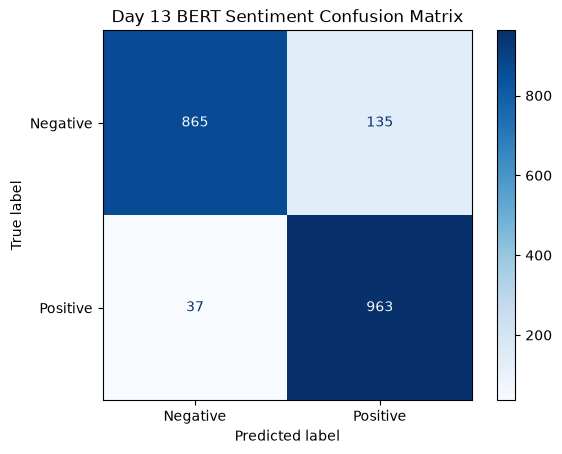

Macro-F1 change over Day 12: +0.0478
BERT fine-tuning time: 121.64 minutes


In [6]:
bert_sentiment_predictions, bert_sentiment_probabilities = predict_transformer_model(
    sentiment_model,
    sentiment_test_loader
)

baseline_report = classification_report(
    y_test,
    day12_baseline_predictions,
    labels=[0, 1],
    target_names=["negative", "positive"],
    output_dict=True,
    zero_division=0
)

bert_sentiment_report = classification_report(
    y_test,
    bert_sentiment_predictions,
    labels=[0, 1],
    target_names=["negative", "positive"],
    output_dict=True,
    zero_division=0
)

sentiment_comparison = pd.DataFrame([
    {
        "model": "Day 12 TF-IDF",
        "accuracy": accuracy_score(y_test, day12_baseline_predictions),
        "macro_f1": baseline_report["macro avg"]["f1-score"],
        "weighted_f1": baseline_report["weighted avg"]["f1-score"]
    },
    {
        "model": "Day 13 BERT",
        "accuracy": accuracy_score(y_test, bert_sentiment_predictions),
        "macro_f1": bert_sentiment_report["macro avg"]["f1-score"],
        "weighted_f1": bert_sentiment_report["weighted avg"]["f1-score"]
    }
])

print("Sentiment model comparison")
display(sentiment_comparison)

print("BERT sentiment classification report")
print(classification_report(
    y_test,
    bert_sentiment_predictions,
    labels=[0, 1],
    target_names=["negative", "positive"],
    zero_division=0
))

sentiment_per_class = pd.DataFrame({
    "Day 12 TF-IDF F1": [
        baseline_report["negative"]["f1-score"],
        baseline_report["positive"]["f1-score"]
    ],
    "Day 13 BERT F1": [
        bert_sentiment_report["negative"]["f1-score"],
        bert_sentiment_report["positive"]["f1-score"]
    ]
}, index=["negative", "positive"])

print("Per-class F1 comparison")
display(sentiment_per_class)

cm = confusion_matrix(y_test, bert_sentiment_predictions, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Day 13 BERT Sentiment Confusion Matrix")
plt.show()

sentiment_f1_lift = (
    bert_sentiment_report["macro avg"]["f1-score"] -
    baseline_report["macro avg"]["f1-score"]
)

print(f"Macro-F1 change over Day 12: {sentiment_f1_lift:+.4f}")
print(f"BERT fine-tuning time: {sentiment_training_seconds / 60:.2f} minutes")

In [7]:
ticket_keywords = {
    "delivery_shipping": [
        "delivery", "delivered", "shipping", "shipment", "arrived",
        "arrival", "package", "parcel", "courier", "tracking", "late"
    ],
    "product_quality": [
        "quality", "broken", "defective", "defect", "damaged",
        "damage", "durable", "material", "stopped working", "cracked"
    ],
    "customer_service": [
        "customer service", "support", "seller", "return", "refund",
        "replacement", "response", "contact", "help", "complaint"
    ],
    "price_value": [
        "price", "expensive", "cheap", "value", "money", "cost",
        "worth", "overpriced", "affordable"
    ],
    "usability_features": [
        "easy to use", "difficult to use", "feature", "setup",
        "install", "design", "size", "comfortable", "battery",
        "instructions", "works", "working"
    ]
}


def assign_ticket_category(text):
    review = str(text).lower()
    category_scores = {}

    for category, keywords in ticket_keywords.items():
        score = 0

        for keyword in keywords:
            if " " in keyword:
                score += review.count(keyword)
            else:
                score += len(re.findall(
                    rf"\b{re.escape(keyword)}\b",
                    review
                ))

        category_scores[category] = score

    best_category = max(category_scores, key=category_scores.get)

    if category_scores[best_category] == 0:
        return None

    return best_category


ticket_data = reviews[["review_text"]].copy()
ticket_data["ticket_category"] = ticket_data["review_text"].apply(
    assign_ticket_category
)
ticket_data = ticket_data.dropna(subset=["ticket_category"]).reset_index(drop=True)

ticket_counts = ticket_data["ticket_category"].value_counts()
MIN_CATEGORY_SAMPLES = 25
valid_ticket_categories = ticket_counts[
    ticket_counts >= MIN_CATEGORY_SAMPLES
].index.tolist()

ticket_data = ticket_data[
    ticket_data["ticket_category"].isin(valid_ticket_categories)
].reset_index(drop=True)

ticket_labels = sorted(ticket_data["ticket_category"].unique())

if len(ticket_labels) < 2:
    raise ValueError(
        "Not enough support-ticket categories were found. "
        "Use a larger review sample or lower MIN_CATEGORY_SAMPLES."
    )

ticket_label2id = {
    category: index for index, category in enumerate(ticket_labels)
}
ticket_id2label = {
    index: category for category, index in ticket_label2id.items()
}

ticket_data["label"] = ticket_data["ticket_category"].map(ticket_label2id)

print("Support-ticket categories are derived from review keywords.")
print("These are weak labels from review text, not manually annotated tickets.")
display(ticket_data["ticket_category"].value_counts())
print("Ticket examples:", len(ticket_data))
print("Categories:", ticket_labels)

Support-ticket categories are derived from review keywords.
These are weak labels from review text, not manually annotated tickets.


ticket_category
price_value           1506
usability_features     799
product_quality        761
customer_service       693
delivery_shipping      384
Name: count, dtype: int64

Ticket examples: 4143
Categories: ['customer_service', 'delivery_shipping', 'price_value', 'product_quality', 'usability_features']


In [8]:
X_ticket_train, X_ticket_test, y_ticket_train, y_ticket_test = train_test_split(
    ticket_data["review_text"],
    ticket_data["label"],
    test_size=0.2,
    random_state=42,
    stratify=ticket_data["label"]
)

X_ticket_train = X_ticket_train.reset_index(drop=True)
X_ticket_test = X_ticket_test.reset_index(drop=True)
y_ticket_train = y_ticket_train.reset_index(drop=True)
y_ticket_test = y_ticket_test.reset_index(drop=True)

ticket_train_limit = min(MAX_TICKET_TRAIN_ROWS, len(X_ticket_train))

if len(X_ticket_train) > ticket_train_limit:
    X_ticket_bert_train, _, y_ticket_bert_train, _ = train_test_split(
        X_ticket_train,
        y_ticket_train,
        train_size=ticket_train_limit,
        random_state=42,
        stratify=y_ticket_train
    )
else:
    X_ticket_bert_train = X_ticket_train.copy()
    y_ticket_bert_train = y_ticket_train.copy()

X_ticket_fit, X_ticket_val, y_ticket_fit, y_ticket_val = train_test_split(
    X_ticket_bert_train,
    y_ticket_bert_train,
    test_size=0.1,
    random_state=42,
    stratify=y_ticket_bert_train
)

ticket_train_dataset = make_text_dataset(
    X_ticket_fit,
    y_ticket_fit,
    tokenizer
)
ticket_validation_dataset = make_text_dataset(
    X_ticket_val,
    y_ticket_val,
    tokenizer
)
ticket_test_dataset = make_text_dataset(
    X_ticket_test,
    y_ticket_test,
    tokenizer
)

ticket_train_loader = DataLoader(
    ticket_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)
ticket_validation_loader = DataLoader(
    ticket_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
ticket_test_loader = DataLoader(
    ticket_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Ticket training rows:", len(X_ticket_fit))
print("Ticket validation rows:", len(X_ticket_val))
print("Ticket test rows:", len(X_ticket_test))

Ticket training rows: 2700
Ticket validation rows: 300
Ticket test rows: 829


In [9]:
ticket_model = AutoModelForSequenceClassification.from_pretrained(
    SENTIMENT_MODEL_DIR,
    num_labels=len(ticket_labels),
    id2label=ticket_id2label,
    label2id=ticket_label2id,
    ignore_mismatched_sizes=True
)

ticket_start_time = time.perf_counter()

ticket_history = train_transformer_model(
    ticket_model,
    ticket_train_loader,
    ticket_validation_loader,
    epochs=TICKET_EPOCHS
)

ticket_training_seconds = time.perf_counter() - ticket_start_time

ticket_predictions, ticket_probabilities = predict_transformer_model(
    ticket_model,
    ticket_test_loader
)

ticket_report = classification_report(
    y_ticket_test,
    ticket_predictions,
    labels=list(range(len(ticket_labels))),
    target_names=ticket_labels,
    output_dict=True,
    zero_division=0
)

print("Support-ticket classification report")
print(classification_report(
    y_ticket_test,
    ticket_predictions,
    labels=list(range(len(ticket_labels))),
    target_names=ticket_labels,
    zero_division=0
))

ticket_per_class_f1 = pd.DataFrame({
    "category": ticket_labels,
    "precision": [
        ticket_report[category]["precision"] for category in ticket_labels
    ],
    "recall": [
        ticket_report[category]["recall"] for category in ticket_labels
    ],
    "f1_score": [
        ticket_report[category]["f1-score"] for category in ticket_labels
    ],
    "support": [
        ticket_report[category]["support"] for category in ticket_labels
    ]
})

display(ticket_per_class_f1)

print(
    "Ticket accuracy:",
    round(accuracy_score(y_ticket_test, ticket_predictions), 4)
)
print(
    "Ticket macro F1:",
    round(ticket_report["macro avg"]["f1-score"], 4)
)

[transformers] You passed `num_labels=5` which is incompatible to the `id2label` map of length `2`.
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 494.48it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\nlp\retailmind_bert_sentiment
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([5, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([5])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch 1/1 - Batch 50/338 - Loss: 1.5257
Epoch 1/1 - Batch 100/338 - Loss: 1.4632
Epoch 1/1 - Batch 150/338 - Loss: 1.3722
Epoch 1/1 - Batch 200/338 - Loss: 0.8754
Epoch 1/1 - Batch 250/338 - Loss: 1.5694
Epoch 1/1 - Batch 300/338 - Loss: 0.7220
Epoch 1: train loss=1.2324, validation loss=0.7389
Support-ticket classification report
                    precision    recall  f1-score   support

  customer_service       0.69      0.44      0.54       139
 delivery_shipping       0.77      0.75      0.76        77
       price_value       0.80      0.90      0.85       301
   product_quality       0.80      0.68      0.73       152
usability_features       0.66      0.82      0.73       160

          accuracy                           0.75       829
         macro avg       0.74      0.72      0.72       829
      weighted avg       0.75      0.75      0.74       829



,category,precision,recall,f1_score,support
0,customer_service,0.685393,0.438849,0.535088,139.0
1,delivery_shipping,0.773333,0.753247,0.763158,77.0
2,price_value,0.803571,0.897010,0.847724,301.0
3,product_quality,0.798450,0.677632,0.733096,152.0
4,usability_features,0.655000,0.818750,0.727778,160.0


Ticket accuracy: 0.7515
Ticket macro F1: 0.7214


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.25it/s]


Saved ticket-routing model: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\nlp\retailmind_bert_ticket_router
Ticket model training time: 82.95 minutes


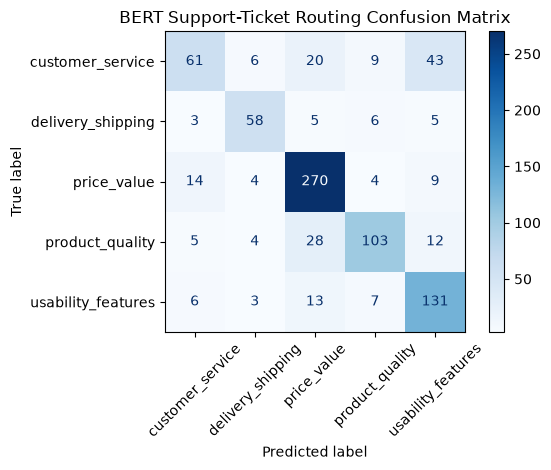

In [10]:
TICKET_MODEL_DIR.mkdir(parents=True, exist_ok=True)
ticket_model.save_pretrained(TICKET_MODEL_DIR)
tokenizer.save_pretrained(TICKET_MODEL_DIR)

ticket_metadata = {
    "categories": ticket_labels,
    "label2id": ticket_label2id,
    "id2label": ticket_id2label,
    "label_source": "Keyword-derived weak labels from Amazon reviews",
    "max_length": MAX_LENGTH
}

with open(
    TICKET_MODEL_DIR / "ticket_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(ticket_metadata, file, indent=4)

print("Saved ticket-routing model:", TICKET_MODEL_DIR)
print(f"Ticket model training time: {ticket_training_seconds / 60:.2f} minutes")

ticket_cm = confusion_matrix(
    y_ticket_test,
    ticket_predictions,
    labels=list(range(len(ticket_labels)))
)

ticket_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=ticket_cm,
    display_labels=ticket_labels
)
ticket_cm_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)
plt.title("BERT Support-Ticket Routing Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
module_code = r'''import json
from functools import lru_cache
from pathlib import Path

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer


def _project_root():
    return Path(__file__).resolve().parents[1]


@lru_cache(maxsize=4)
def _load_text_model(model_dir):
    model_path = Path(model_dir)

    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    return tokenizer, model, device


def _predict_text(text, model_dir):
    tokenizer, model, device = _load_text_model(str(model_dir))

    encoded = tokenizer(
        str(text),
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        outputs = model(**encoded)
        probabilities = torch.softmax(outputs.logits, dim=1)[0]

    predicted_id = int(torch.argmax(probabilities).item())
    confidence = float(probabilities[predicted_id].item())

    id2label = model.config.id2label
    predicted_label = id2label.get(
        predicted_id,
        id2label.get(str(predicted_id), f"LABEL_{predicted_id}")
    )

    return {
        "category": str(predicted_label).lower(),
        "label": predicted_id,
        "confidence": confidence
    }


def predict_review_sentiment(review_text, model_dir=None, model_path=None):
    if model_dir is None:
        if model_path and Path(model_path).is_dir():
            model_dir = model_path
        else:
            model_dir = (
                _project_root()
                / "models"
                / "nlp"
                / "retailmind_bert_sentiment"
            )

    result = _predict_text(review_text, model_dir)

    return {
        "sentiment": result["category"],
        "label": result["label"],
        "confidence": result["confidence"]
    }


def route_support_ticket(ticket_text, model_dir=None):
    if model_dir is None:
        model_dir = (
            _project_root()
            / "models"
            / "nlp"
            / "retailmind_bert_ticket_router"
        )

    result = _predict_text(ticket_text, model_dir)

    return {
        "category": result["category"],
        "label": result["label"],
        "confidence": result["confidence"]
    }
'''

module_path = SRC_DIR / "review_processor.py"
module_path.write_text(module_code, encoding="utf-8")

print("Updated BERT-powered text module:", module_path)

Updated BERT-powered text module: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\review_processor.py


In [12]:
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

importlib.invalidate_caches()

if "review_processor" in sys.modules:
    importlib.reload(sys.modules["review_processor"])
else:
    import review_processor

from review_processor import (
    predict_review_sentiment,
    route_support_ticket
)

review_examples = [
    "The product quality is excellent and I am very happy with this purchase.",
    "The item arrived broken and stopped working after two days."
]

ticket_examples = [
    "My package has not arrived and the delivery is late.",
    "The product is defective and I need a replacement."
]

for review in review_examples:
    print("Review:", review)
    print("Sentiment:", predict_review_sentiment(review))
    print()

for ticket in ticket_examples:
    print("Ticket:", ticket)
    print("Routing:", route_support_ticket(ticket))
    print()

Review: The product quality is excellent and I am very happy with this purchase.


Loading weights: 100%|██████████| 201/201 [00:01<00:00, 116.13it/s]


Sentiment: {'sentiment': 'positive', 'label': 1, 'confidence': 0.9914811849594116}

Review: The item arrived broken and stopped working after two days.
Sentiment: {'sentiment': 'negative', 'label': 0, 'confidence': 0.9925587177276611}

Ticket: My package has not arrived and the delivery is late.


Loading weights: 100%|██████████| 201/201 [00:02<00:00, 82.22it/s] 


Routing: {'category': 'delivery_shipping', 'label': 1, 'confidence': 0.7679119110107422}

Ticket: The product is defective and I need a replacement.
Routing: {'category': 'product_quality', 'label': 3, 'confidence': 0.8848273158073425}



In [13]:
sentiment_metrics = {
    "day12_tfidf": {
        "accuracy": float(accuracy_score(y_test, day12_baseline_predictions)),
        "macro_f1": float(baseline_report["macro avg"]["f1-score"]),
        "weighted_f1": float(baseline_report["weighted avg"]["f1-score"])
    },
    "day13_bert": {
        "accuracy": float(accuracy_score(y_test, bert_sentiment_predictions)),
        "macro_f1": float(bert_sentiment_report["macro avg"]["f1-score"]),
        "weighted_f1": float(bert_sentiment_report["weighted avg"]["f1-score"]),
        "training_seconds": float(sentiment_training_seconds)
    },
    "macro_f1_change": float(sentiment_f1_lift),
    "baseline_source": day12_baseline_source
}

ticket_metrics = {
    "accuracy": float(accuracy_score(y_ticket_test, ticket_predictions)),
    "macro_f1": float(ticket_report["macro avg"]["f1-score"]),
    "weighted_f1": float(ticket_report["weighted avg"]["f1-score"]),
    "training_seconds": float(ticket_training_seconds),
    "categories": ticket_labels,
    "label_source": "Keyword-derived weak labels from Amazon reviews"
}

metrics_output = {
    "sentiment": sentiment_metrics,
    "ticket_routing": ticket_metrics
}

with open(
    REPORT_DIR / "day13_bert_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics_output, file, indent=4)

sentiment_comparison.to_csv(
    REPORT_DIR / "sentiment_model_comparison.csv",
    index=False
)
sentiment_per_class.to_csv(
    REPORT_DIR / "sentiment_per_class_f1.csv"
)
ticket_per_class_f1.to_csv(
    REPORT_DIR / "ticket_per_class_f1.csv",
    index=False
)

print("Saved Day 13 metrics and reports:", REPORT_DIR)
print("Sentiment comparison")
display(sentiment_comparison)
print("Ticket per-class F1")
display(ticket_per_class_f1)

Saved Day 13 metrics and reports: c:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day13_bert
Sentiment comparison


,model,accuracy,macro_f1,weighted_f1
0,Day 12 TF-IDF,0.866,0.865995,0.865995
1,Day 13 BERT,0.914,0.913793,0.913793


Ticket per-class F1


,category,precision,recall,f1_score,support
0,customer_service,0.685393,0.438849,0.535088,139.0
1,delivery_shipping,0.773333,0.753247,0.763158,77.0
2,price_value,0.803571,0.897010,0.847724,301.0
3,product_quality,0.798450,0.677632,0.733096,152.0
4,usability_features,0.655000,0.818750,0.727778,160.0
